# Zernikes

Launch the coefficient editor for an existing `Zernikes` instance.

Requires an editable install: `pip install -e ".[gui,notebooks]"`.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
%gui qt

In [3]:
from pylab import *

In [4]:
import zernikes
print("zernikes", zernikes.__version__)

In [5]:
from zernikes import Zernikes
from zernikes.ui import ZernikesWidget

In [6]:
z = Zernikes(
    max_zernike_radial_number=6,
    mask_size_x_in_pixels=960,
    mask_size_y_in_pixels=960,
    aperture_diameter_in_m=7.5e-3,   # match pyLCOS defaults
    SLM_pixel_size_in_um=9.2e-6
)

In [7]:
z.filter_coefficients_by_aberration_keys( 'H', 'tilt'  )

(array([0., 0.], dtype=float32), [1, 2])

# Widget Interface

In [8]:
gui = ZernikesWidget(z)
gui.show()

# Manipulate the zernike engine

In [13]:
z.tilt_x_v = 11

In [14]:
z.calculate_znk_phase_mask() #Generate the Mask base in coeffs.

In [15]:
gui.refresh_from_zernikes() # Updates widget with internal coefs

In [16]:
gui._regenerate_phase() # Calls z.calculate_znk_phase_mask() and display new masks in the viewport

In [11]:
# Matplotlib displaying

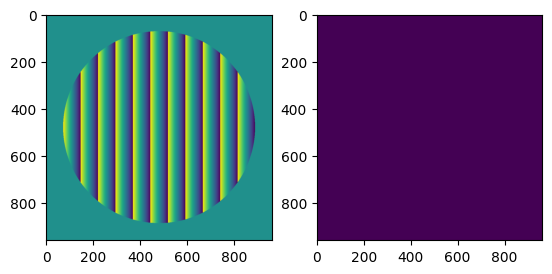

In [14]:
fig, ax = subplots(1,2)

ax[0].imshow(z.znk_phase_h)
ax[1].imshow(z.znk_phase_v)

In [21]:
znk_table = z.generate_table()
znk_table

,index,n,m,H,V,name
0,0,0,0,0.0,0.0,Piston
1,1,1,-1,11.0,0.0,Tilt X
2,2,1,1,0.0,0.0,Tilt Y
3,3,2,-2,0.0,0.0,Astigmatism 45°
4,4,2,0,0.0,0.0,Defocus
5,5,2,2,0.0,0.0,Astigmatism 0°/90°
6,6,3,-3,0.0,0.0,Trefoil Y
7,7,3,-1,0.0,0.0,Coma Y
8,8,3,1,0.0,0.0,Coma X
9,9,3,3,0.0,0.0,Trefoil X


AttributeError: 'Zernikes' object has no attribute 'table_output'

In [19]:
import pandas as pd


ModuleNotFoundError: No module named 'pandas'